# Part B: diversity of names and stability of the top-10


Data: US Social Security Administration (SSA), national baby names 1880–2025
(https://www.ssa.gov/oact/babynames/limits.html). One file `yobYYYY.txt` per year with columns
`name, sex, count`; names given to fewer than 5 babies in a year are not published.


In [17]:
%pip install -q numpy pandas scipy matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
import io, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

## 1. Load the data

In [19]:

def load_names(zip_path="/content/drive/MyDrive/names.zip", data_dir="data/names"):
    data_dir = Path(data_dir)
    if not any(data_dir.glob("yob*.txt")):
        data_dir.mkdir(parents=True, exist_ok=True)
        zipfile.ZipFile(zip_path).extractall(data_dir)

    frames = []
    for path in sorted(data_dir.glob("yob*.txt")):
        df = pd.read_csv(path, header=None, names=["name", "sex", "count"])
        df["year"] = int(path.stem[3:])
        frames.append(df)
    names = pd.concat(frames, ignore_index=True)

    names["rank"] = (names.groupby(["year", "sex"])["count"].rank(method="first", ascending=False).astype(int))
    names["share"] = names["count"] / names.groupby(["year", "sex"])["count"].transform("sum")
    return names

names = load_names(zip_path="names.zip")
print(f"{len(names):,} rows, years {names.year.min()}–{names.year.max()}")
print(names.groupby("sex").size()) #кількість імен а не дітей
names[names.year == 2025].groupby("sex").head(5)

2,181,032 rows, years 1880–2025
sex
F    1280901
M     900131
dtype: int64


,name,sex,count,year,rank,share
2149805,Olivia,F,13544,2025,1,0.008427
2149806,Charlotte,F,13400,2025,2,0.008337
2149807,Emma,F,12754,2025,3,0.007935
2149808,Amelia,F,12699,2025,4,0.007901
2149809,Sophia,F,12561,2025,5,0.007815
2167102,Liam,M,20818,2025,1,0.012188
2167103,Noah,M,20358,2025,2,0.011919
2167104,Oliver,M,14939,2025,3,0.008746
2167105,Theodore,M,13355,2025,4,0.007819
2167106,Henry,M,12020,2025,5,0.007037


## 2. Name diversity over time

We measure how concentrated or diverse names are in each year, separately for girls and boys.

- **Shannon entropy.** If $p_i$ is the share of babies given name $i$ in a year, then
  $H = -\sum_i p_i \log_2 p_i$ (in bits). $H$ is larger when births are spread over many
  names with similar popularity. $2^H$ can be read as the "effective number" of equally
  popular names.
- **Top-10 share.** The percentage of all babies of that sex who received one of the 10 most
  popular names. It is a simple and robust measure of concentration at the top.

In [20]:
def diversity_measures(group):
    x = group['count'].to_numpy(dtype=float)
    p = x / x.sum()
    return pd.Series({
        'births': x.sum(),
        'distinct names': len(x),
        'entropy, bits': -(p * np.log2(p)).sum(),
        'top-10 share, %': 100*np.sort(x)[::-1][:10].sum() / x.sum(),
    })

diversity = (names.groupby(['sex', 'year'])[['count']]
             .apply(diversity_measures)
             .reset_index())
diversity.head()

,sex,year,births,distinct names,"entropy, bits","top-10 share, %"
0,F,1880,90994.0,942.0,7.591849,24.648878
1,F,1881,91953.0,938.0,7.599520,24.154731
2,F,1882,107847.0,1028.0,7.638406,23.941324
3,F,1883,112320.0,1054.0,7.678668,23.422365
4,F,1884,129019.0,1172.0,7.733801,23.143878


In [21]:
check = diversity[diversity.year.isin([1950, 1980, 2000, 2010, 2025])]
check.pivot(index="year", columns="sex",
            values=["top-10 share, %", "entropy, bits"]).round(2)

top-10 share, %        entropy, bits       
sex                F      M             F      M
year                                            
1950           24.10  33.80          8.28   7.48
1980           17.10  23.58          9.47   8.26
2000           10.22  13.37         10.44   9.38
2010            8.87   8.97         10.99  10.00
2025            6.99   7.98         11.05  10.43

In 1950, 33.8% of boys and 24.1% of girls received a top-10 name; in 2025 it was only 8.0% and  7.0%. Over the same period entropy rose from 7.48 to 10.43 bits for boys and from 8.28 to 11.05 bits for girls, so the 'effective number' of names grew roughly 8 times for boys ($2^{10.43-7.48} \approx 7.7$) and 7 times for girls.

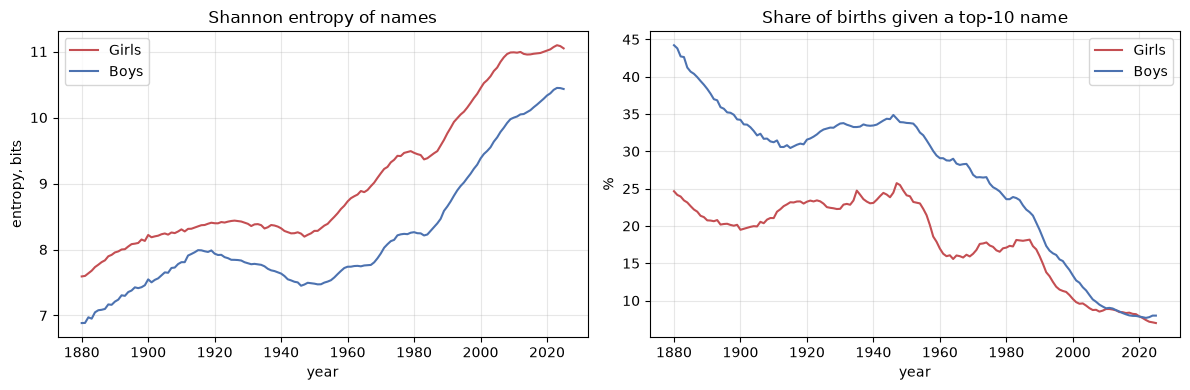

In [22]:
COLORS = {"F": "#C44E52", "M": "#4C72B0"}
LABELS = {"F": "Girls", "M": "Boys"}

def plot_diversity(diversity, start_year=1880):
    d = diversity[diversity.year >= start_year]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for sex in ["F", "M"]:
        s = d[d.sex == sex]
        axes[0].plot(s["year"], s["entropy, bits"], color=COLORS[sex], label=LABELS[sex])
        axes[1].plot(s["year"], s["top-10 share, %"], color=COLORS[sex], label=LABELS[sex])
    axes[0].set_title("Shannon entropy of names")
    axes[0].set_ylabel("entropy, bits")
    axes[1].set_title("Share of births given a top-10 name")
    axes[1].set_ylabel("%")
    for ax in axes:
        ax.set_xlabel("year"); ax.grid(alpha=0.3); ax.legend()
    plt.tight_layout(); plt.show()

plot_diversity(diversity)

**Long-run trend.** Diversity was roughly flat or even falling until about 1950 (for boys the top-10 share actually rose from about 31% to 35% in 1915–1947). After 1950 entropy rises
steadily and the top-10 share falls sharply for both sexes.


**Girls' names have been more diverse for the whole period**: girls' entropy is higher
in every year. Boys have been catching up, and by about 2010 the top-10 shares of the two
sexes became almost equal.


**The trend is not linear.** There are periods of stagnation and fast growth, so a single
straight line over 1880–2025 would describe the data poorly.





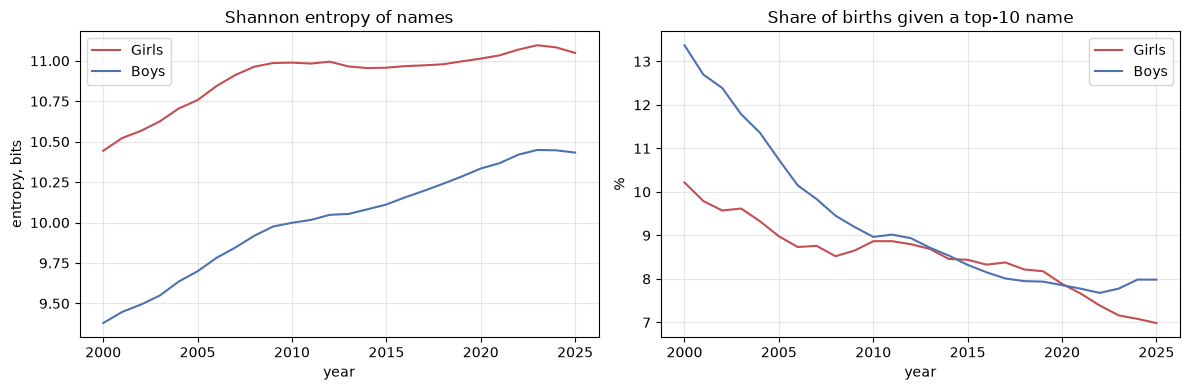

entropy, bits         top-10 share, %       
sex              F       M               F      M
year                                             
2010        10.989   9.999           8.865  8.965
2011        10.983  10.016           8.867  9.018
2012        10.994  10.048           8.797  8.934
2013        10.965  10.053           8.689  8.718
2014        10.955  10.082           8.458  8.536
2015        10.957  10.112           8.439  8.322
2016        10.967  10.156           8.327  8.152
2017        10.972  10.196           8.377  8.009
2018        10.978  10.240           8.217  7.949
2019        10.997  10.285           8.175  7.937
2020        11.013  10.334           7.886  7.857
2021        11.034  10.367           7.660  7.773
2022        11.069  10.420           7.389  7.678
2023        11.096  10.449           7.161  7.776
2024        11.083  10.447           7.081  7.984
2025        11.049  10.433           6.985  7.983

In [23]:
plot_diversity(diversity, start_year=2000)
(diversity[diversity.year >= 2010]
 .pivot(index="year", columns="sex", values=["entropy, bits", "top-10 share, %"])
 .round(3))

**A closer look at the last 15 years.**


- **Girls:** entropy stayed almost flat from 2009 to 2018 (around 10.96–10.99 bits), then grew again to a maximum of 11.10 bits in 2023, and slightly decreased in 2024–2025.
- **Boys:** entropy kept growing every year until 2023 (10.45 bits), then also slightly decreased.
- **Boys' top-10 share** stopped falling around 2018 (about 7.9–8.0%) and even rose a little in 2024–2025.


So the strong upward trend in diversity may be slowing down. This motivates H2: instead of
only testing "entropy increases over time" (which is obvious from the plot), we can test
whether the slope in recent years is significantly smaller than before.

## 3. How stable is the top-10?

For each year we take the set of top-10 names and count how many of them are still in the
top-10 in the next year (from 0 to 10). This tells us how hard it is to forecast the top-10:
if almost all names stay, the naive forecast "same as last year" is already very good.

In [24]:
top10 = (names[names["rank"] <= 10]
         .groupby(["sex", "year"])["name"]
         .apply(set))

rows = []
for (sex, year), current in top10.items():
    nxt = top10.get((sex, year + 1))
    if nxt is not None:
        rows.append({"sex": sex, "year": year, "stayed in top-10": len(current & nxt)})
stability = pd.DataFrame(rows)

print(stability.groupby("sex")["stayed in top-10"].describe().round(2))
stability.groupby("sex")["stayed in top-10"].value_counts().sort_index()

     count  mean   std  min  25%   50%   75%   max
sex                                               
F    145.0  9.26  0.65  7.0  9.0   9.0  10.0  10.0
M    145.0  9.44  0.62  8.0  9.0  10.0  10.0  10.0


sex  stayed in top-10
F    7                    2
     8                   11
     9                   80
     10                  52
M    8                   10
     9                   61
     10                  74
Name: count, dtype: int64

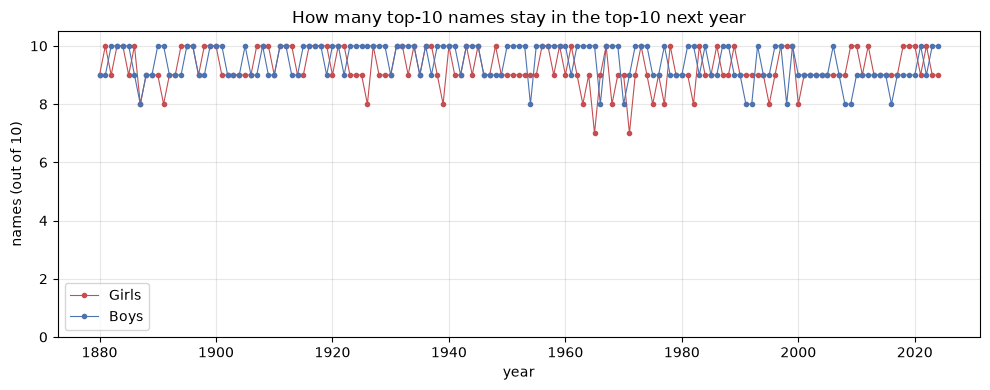

In [25]:
fig, ax = plt.subplots(figsize=(10, 4))
for sex in ["F", "M"]:
    s = stability[stability.sex == sex]
    ax.plot(s["year"], s["stayed in top-10"], color=COLORS[sex], label=LABELS[sex],
            marker=".", lw=0.8)
ax.set_ylim(0, 10.5)
ax.set_xlabel("year"); ax.set_ylabel("names (out of 10)")
ax.set_title("How many top-10 names stay in the top-10 next year")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [26]:
for sex in ["F", "M"]:
    left = top10[(sex, 2024)] - top10[(sex, 2025)]
    entered = top10[(sex, 2025)] - top10[(sex, 2024)]
    print(f"{LABELS[sex]}: left the top-10 {left or '-'}, entered {entered or '-'}")

Girls: left the top-10 {'Ava'}, entered {'Eliana'}
Boys: left the top-10 -, entered -


**The top-10 is very stable.** On average 9.3 of the 10 girls' names and 9.4 of the 10 boys'
names stay in the top-10 the next year.  In 145 year-to-year transitions, the girls' top-10 never lost more than 3 names and the boys' never more than 2.


**2024 → 2025:** the boys' top-10 did not change at all; for girls only one name changed
(Ava left, Eliana entered).


**Consequence for the forecast:** "same as last year" will correctly predict about 9 of the 10 names, so it is a strong baseline. A useful model must beat it on the 1–2 names that change.

## 4. How long does a name stay in the top-10?


A **spell** is a period of consecutive years during which a name is in the top-10. For example, Michael was in the boys' top-10 every year from 1943 to 2016, which is one spell of 74 years.

**Model.** Suppose that every year a name in the top-10 leaves it with the same probability $q$, regardless of how long it has already been there. Then the spell length $L$ follows a
**geometric distribution**:

$$P(L = k) = (1-q)^{k-1}\,q, \qquad k = 1, 2, \dots, \qquad E[L] = \frac{1}{q}.$$

This distribution is **memoryless**: a name that has been in the top-10 for 20 years is as likely to leave next year as a name that has just entered. Testing this model tells us whether name fashion "has a memory".

**Incomplete spells.** Spells that started in 1880 or are still going on in 2025 are cut by the edges of the data, so we do not know their true length. We use only complete spells.


In [27]:
FIRST, LAST = names.year.min(), names.year.max()

top = (names[names["rank"] <= 10][["sex", "name", "year"]]
       .sort_values(["sex", "name", "year"]))
top["new_spell"] = top.groupby(["sex", "name"])["year"].diff() != 1
top["spell_id"] = top["new_spell"].cumsum()

spells = (top.groupby(["spell_id", "sex", "name"])["year"]
          .agg(start="min", end="max")
          .reset_index())
spells["length"] = spells["end"] - spells["start"] + 1
spells["complete"] = (spells["start"] > FIRST) & (spells["end"] < LAST)
complete = spells[spells["complete"]]

print(f"{len(spells)} spells, {len(complete)} complete")
print(complete.groupby("sex")["length"].describe().round(2))
complete.sort_values("length", ascending=False).head(5)

209 spells, 169 complete
     count   mean    std  min   25%  50%    75%    max
sex                                                   
F     98.0  10.51  10.22  1.0  1.25  8.0  16.75   45.0
M     71.0  11.13  18.18  1.0  1.00  4.0  11.00  102.0


,spell_id,sex,name,start,end,length,complete
189,190,M,Robert,1888,1989,102,True
182,183,M,Michael,1943,2016,74,True
136,137,M,David,1936,1992,57,True
186,187,M,Richard,1920,1970,51,True
58,59,F,Helen,1891,1935,45,True


**Estimating $q$.** Since $E[L] = 1/q$, the maximum likelihood estimate is
$\hat q = 1/\bar L$, where $\bar L$ is the mean spell length.

**Chi-square goodness-of-fit test.**

- $H_0$: spell lengths follow a geometric distribution.
- $H_1$: they do not.


We group the lengths into bins (1, 2, 3–4, 5–8, …), so that every bin has an expected count of at least 5 for each bin we compare the observed number of spells $O_j$ with the number expected under the geometric model $E_j = n \cdot P(L \in \text{bin } j)$ and compute
$\chi^2 = \sum_j \frac{(O_j - E_j)^2}{E_j}$. Under $H_0$ it approximately follows a chi-square distribution with (number of bins − 1 − 1) degrees of freedom: we lose one more degree of freedom because $q$ was estimated from the same data.


In [28]:
lengths = complete["length"].to_numpy()
q_hat = 1 / lengths.mean()
print(f"mean length = {lengths.mean():.2f} years, estimated exit probability q = {q_hat:.3f}")

bins = [(1, 1), (2, 2), (3, 4), (5, 8), (9, 16), (17, 32), (33, None)]
rows = []
for a, b in bins:
    if b is None:
        observed = (lengths >= a).sum()
        prob = (1- q_hat) ** (a-1)
        label = f'{a}+'
    else:
        observed = ((lengths >= a) & (lengths <= b)).sum()
        prob = (1- q_hat) ** (a-1) - (1 - q_hat)
        label = str(a) if a == b else f"{a}-{b}"
    rows.append({'length, years': label, 'observed': observed,
                 'expected': len(lengths) * prob})
fit = pd.DataFrame(rows)

chi2 = ((fit['observed'] - fit['expected']) ** 2 / fit['expected']).sum()
dof = len(fit) - 1 - 1
p_value = stats.chi2.sf(chi2, dof)
print(f'chi-square = {chi2:.1f}, df = {dof}, p-value = {p_value:.2g}')
fit.round(1)

mean length = 10.77 years, estimated exit probability q = 0.093
chi-square = inf, df = 5, p-value = 0


,"length, years",observed,expected
0,1,46,15.7
1,2,17,0.0
2,3-4,15,-14.2
3,5-8,21,-38.9
4,9-16,34,-75.8
5,17-32,24,-117.8
6,33+,12,7.5


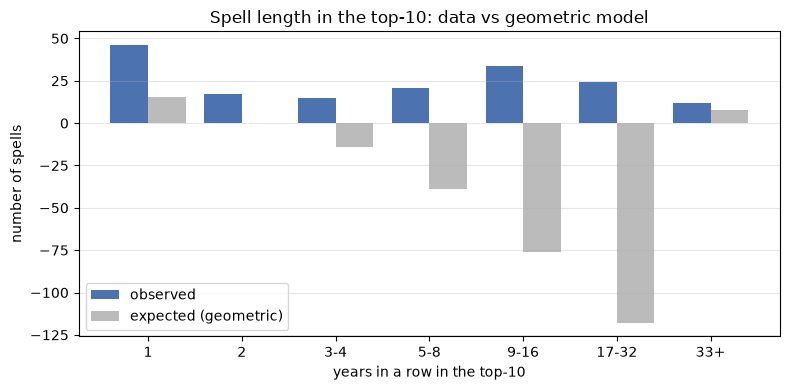

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
pos = np.arange(len(fit))

ax.bar(pos - 0.2, fit["observed"], width=0.4, color="#4C72B0", label="observed")
ax.bar(pos + 0.2, fit["expected"], width=0.4, color="#BBBBBB", label="expected (geometric)")
ax.set_xticks(pos); ax.set_xticklabels(fit["length, years"])
ax.set_xlabel("years in a row in the top-10"); ax.set_ylabel("number of spells")
ax.set_title("Spell length in the top-10: data vs geometric model")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
hazard = pd.DataFrame({
    "year in top-10": np.arange(1, 11),
    "still in top-10": [(lengths >= k).sum() for k in range(1, 11)],
    "left after this year": [(lengths == k).sum() for k in range(1, 11)],
})
hazard["exit probability"] = hazard["left after this year"] / hazard["still in top-10"]
hazard.round(2)

,year in top-10,still in top-10,left after this year,exit probability
0,1,169,46,0.27
1,2,123,17,0.14
2,3,106,5,0.05
3,4,101,10,0.10
4,5,91,8,0.09
5,6,83,2,0.02
6,7,81,5,0.06
7,8,76,6,0.08
8,9,70,6,0.09
9,10,64,5,0.08


**Data.** There are 209 spells, 169 of them complete.The mean complete spell lasts 10.8
  years, so $\hat q = 0.093$. The longest ones are boys' classics: Robert (102 years, 1888–1989), Michael (74 years), David (57 years).

**The geometric model is rejected:** $\chi^2 = 74.6$ with 5 degrees of freedom,
  p-value $\approx 10^{-14}$.

**Why.** There are far more one-year spells than the model predicts (46 instead of 16), fewer medium spells (3–8 years), and more very long ones (33+ years: 12 instead of 7.5).

**Fashion has a memory.** The exit probability is not constant: 27% of names leave the top-10
  after their first year, 14% after the second, and only about 5–10% per year after that.
  *A name that has survived its first years in the top-10 is much more likely to stay.*

**Interpretation:** there seem to be two kinds of popular names: short-lived fashions that
  briefly enter the top-10, and long-lived classics that stay for decades. A single constant $q$
  cannot describe both, which also matters for forecasting the 2027 top-10.

## 5. Names from pop culture

Outside the top-10 names move much faster, and some of the biggest jumps come from films and TV series. The dashed line marks the year of the release.

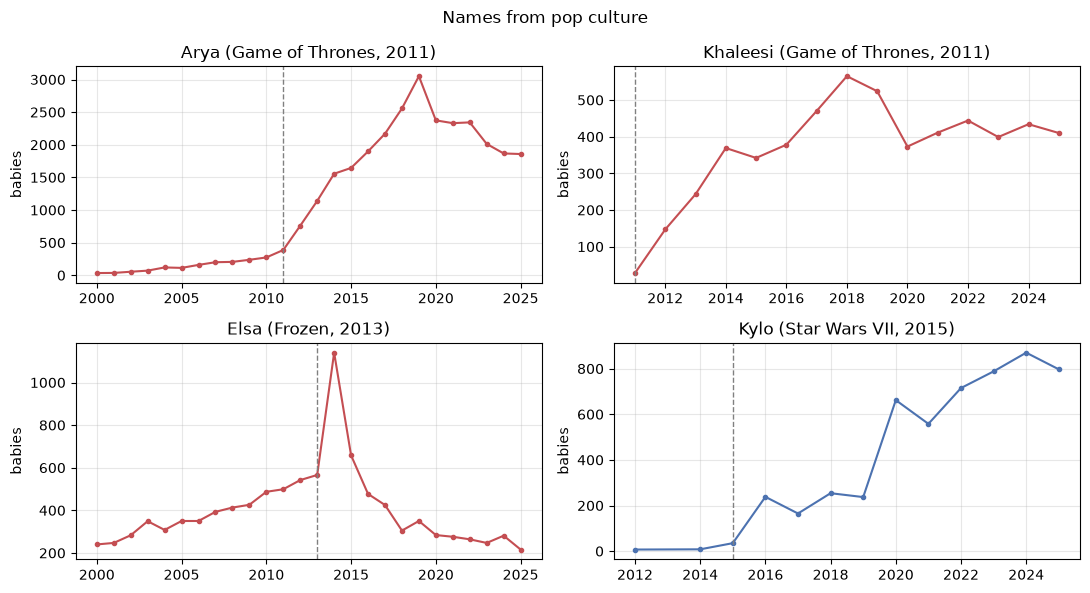

In [31]:
POP = [("Arya", "F", 2011, "Game of Thrones"),
       ("Khaleesi", "F", 2011, "Game of Thrones"),
       ("Elsa", "F", 2013, "Frozen"),
       ("Kylo", "M", 2015, "Star Wars VII")]

fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, (name, sex, event, title) in zip(axes.flat, POP):
    s = names[(names.name == name) & (names.sex == sex) & (names.year >= 2000)]
    ax.plot(s["year"], s["count"], color=COLORS[sex], marker=".")
    ax.axvline(event, color="grey", ls="--", lw=1)
    ax.set_title(f"{name} ({title}, {event})")
    ax.set_ylabel("babies"); ax.grid(alpha=0.3)
plt.suptitle("Names from pop culture")
plt.tight_layout(); plt.show()

**Arya** grew from 387 babies in 2011 to 3,051 in 2019, the year the series ended, and then
  declined.

**Khaleesi** is not a name in the books but a title; it appears in the data only in 2011 and
  reached 565 babies in 2018.

**Elsa** shows a one-year spike: 566 babies in 2013, 1,140 in 2014, and back to 658 in 2015.

**Kylo** was given to fewer than 5 babies a year before the film (some years are missing because of the SSA threshold) and is now given to about 800 babies a year.

Such shocks are unpredictable from past data alone, which is one more reason why forecasting names outside the very stable top-10 is hard.

## 6. Limitations

- SSA does not publish names given to fewer than 5 babies in a year. When fewer babies are
  born, more rare names fall below this threshold and disappear from the data, which lowers
  the measured entropy. The top-10 share is almost unaffected by this threshold, so it is the more reliable of the two measures.

- In early years (before about the 1930s) SSA records do not cover all births, so the early
  part of the series should be interpreted with caution.

- In Section 4 we drop incomplete spells (those starting in 1880 or still going on in 2025). These are mostly long spells, such as Mary (1880-1971) or James (1880-1992), so the true distribution has an even heavier tail than in our data.